KAVYASHREE ENG24CS0094 5B-B1 08/09/2026 EXP 4-LOGISTIC REGRESSION

In [117]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

In [118]:
plt.rcParams['figure.figsize']=[10,5]

In [119]:
import warnings
warnings.filterwarnings('ignore')

In [120]:
df=pd.read_csv('./heart.csv')
df

,Unnamed: 0,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,target
0,0,63,1,3,145,233,1,0,150,0,2.3,0,0,1,1
1,1,37,1,2,130,250,0,1,187,0,3.5,0,0,2,1
2,2,41,0,1,130,204,0,0,172,0,1.4,2,0,2,1
3,3,56,1,1,120,236,0,1,178,0,0.8,2,0,2,1
4,4,57,0,0,120,354,0,1,163,1,0.6,2,0,2,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
298,298,38,0,0,138,214,0,0,166,0,0.3,1,0,2,0
299,299,57,1,0,142,245,0,1,112,1,3.5,2,0,2,1
300,300,70,0,0,129,214,0,1,157,0,1.4,1,0,2,1
301,301,40,0,1,158,191,0,1,129,0,1.0,0,1,1,0


In [121]:
df.shape

(303, 15)

In [122]:
df.head()

,Unnamed: 0,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,target
0,0,63,1,3,145,233,1,0,150,0,2.3,0,0,1,1
1,1,37,1,2,130,250,0,1,187,0,3.5,0,0,2,1
2,2,41,0,1,130,204,0,0,172,0,1.4,2,0,2,1
3,3,56,1,1,120,236,0,1,178,0,0.8,2,0,2,1
4,4,57,0,0,120,354,0,1,163,1,0.6,2,0,2,1


In [123]:
pd.DataFrame({
    'Column': ['age', 'sex', 'cp', 'trestbps', 'chol', 'fbs', 'restecg',
               'thalach', 'exang', 'oldpeak', 'slope', 'ca', 'thal', 'target'],

    'Description': [
        'age in years',
        '(1 = male; 0 = female)',
        'chest pain type',
        'resting blood pressure (in mm Hg on admission to the hospital)',
        'serum cholesterol in mg/dl',
        '(fasting blood sugar > 120 mg/dl) (1 = true; 0 = false)',
        'resting electrocardiographic results',
        'maximum heart rate achieved',
        'exercise induced angina (1 = yes; 0 = no)',
        'ST depression induced by exercise relative to rest',
        'the slope of the peak exercise ST segment',
        'number of major vessels (0-3) colored by flourosopy',
        '0 = normal; 1 = fixed defect; 2 = reversible defect',
        '1 or 0'
    ]
})

,Column,Description
0,age,age in years
1,sex,(1 = male; 0 = female)
2,cp,chest pain type
3,trestbps,resting blood pressure (in mm Hg on admission ...
4,chol,serum cholesterol in mg/dl
5,fbs,(fasting blood sugar > 120 mg/dl) (1 = true; 0...
6,restecg,resting electrocardiographic results
7,thalach,maximum heart rate achieved
8,exang,exercise induced angina (1 = yes; 0 = no)
9,oldpeak,ST depression induced by exercise relative to ...


In [124]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 303 entries, 0 to 302
Data columns (total 15 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   Unnamed: 0  303 non-null    int64  
 1   age         303 non-null    int64  
 2   sex         303 non-null    int64  
 3   cp          303 non-null    int64  
 4   trestbps    303 non-null    int64  
 5   chol        303 non-null    int64  
 6   fbs         303 non-null    int64  
 7   restecg     303 non-null    int64  
 8   thalach     303 non-null    int64  
 9   exang       303 non-null    int64  
 10  oldpeak     303 non-null    float64
 11  slope       303 non-null    int64  
 12  ca          303 non-null    int64  
 13  thal        303 non-null    int64  
 14  target      303 non-null    int64  
dtypes: float64(1), int64(14)
memory usage: 35.6 KB


In [125]:
df.drop('Unnamed: 0', axis=1, inplace=True)


In [126]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 303 entries, 0 to 302
Data columns (total 14 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   age       303 non-null    int64  
 1   sex       303 non-null    int64  
 2   cp        303 non-null    int64  
 3   trestbps  303 non-null    int64  
 4   chol      303 non-null    int64  
 5   fbs       303 non-null    int64  
 6   restecg   303 non-null    int64  
 7   thalach   303 non-null    int64  
 8   exang     303 non-null    int64  
 9   oldpeak   303 non-null    float64
 10  slope     303 non-null    int64  
 11  ca        303 non-null    int64  
 12  thal      303 non-null    int64  
 13  target    303 non-null    int64  
dtypes: float64(1), int64(13)
memory usage: 33.3 KB


In [127]:
df.describe()

,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,target
count,303.000000,303.000000,303.000000,303.000000,303.000000,303.000000,303.000000,303.000000,303.000000,303.000000,303.000000,303.000000,303.000000,303.000000
mean,53.963696,0.660066,0.930693,132.244224,246.396040,0.158416,0.491749,150.722772,0.330033,1.072937,1.033003,0.765677,2.247525,0.551155
std,8.435694,0.474470,1.028637,16.426228,53.975113,0.365734,0.532796,23.409450,0.471003,1.004358,0.745116,1.033164,0.631501,0.498199
min,31.000000,0.000000,0.000000,94.000000,126.000000,0.000000,0.000000,79.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,48.000000,0.000000,0.000000,122.000000,211.000000,0.000000,0.000000,135.000000,0.000000,0.300000,0.000000,0.000000,2.000000,0.000000
50%,54.000000,1.000000,1.000000,132.000000,246.000000,0.000000,0.000000,152.000000,0.000000,0.800000,1.000000,0.000000,2.000000,1.000000
75%,59.000000,1.000000,2.000000,142.000000,281.500000,0.000000,1.000000,165.000000,1.000000,1.500000,2.000000,1.000000,3.000000,1.000000
max,77.000000,1.000000,3.000000,181.000000,387.000000,1.000000,2.000000,202.000000,1.000000,5.000000,2.000000,4.000000,3.000000,1.000000


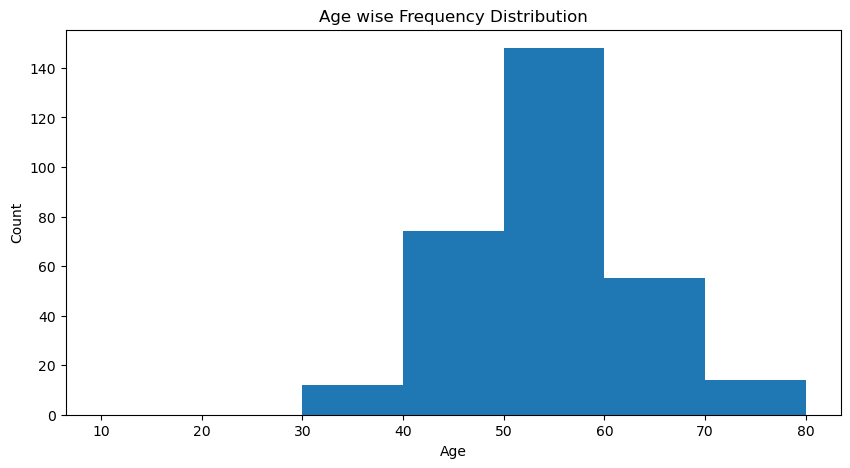

In [128]:
plt.hist(df['age'], bins=[10, 20, 30, 40, 50, 60, 70, 80])
plt.title("Age wise Frequency Distribution")
plt.xlabel("Age")
plt.ylabel("Count")
plt.show()

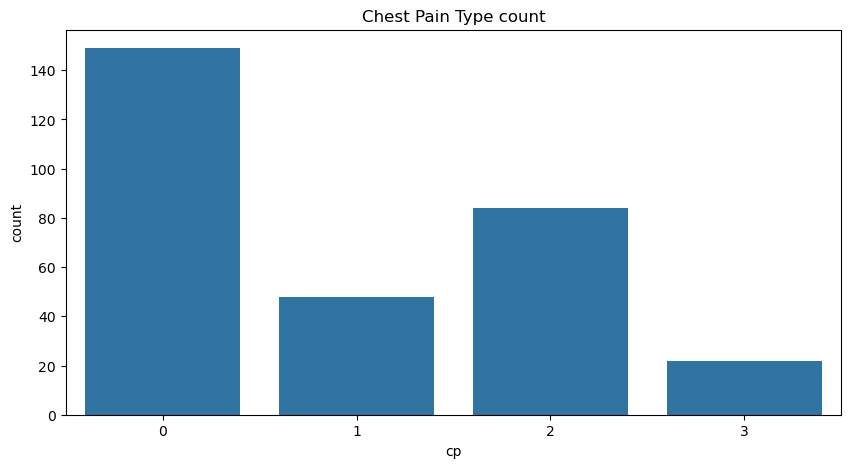

In [129]:
sns.countplot(data=df, x='cp')
plt.title("Chest Pain Type count")
plt.show()


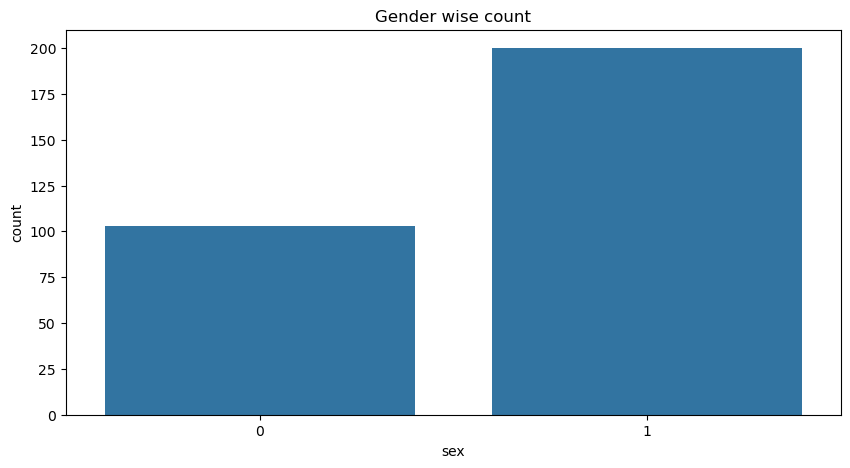

In [130]:
sns.countplot(data=df, x='sex')
plt.title("Gender wise count")
plt.show()


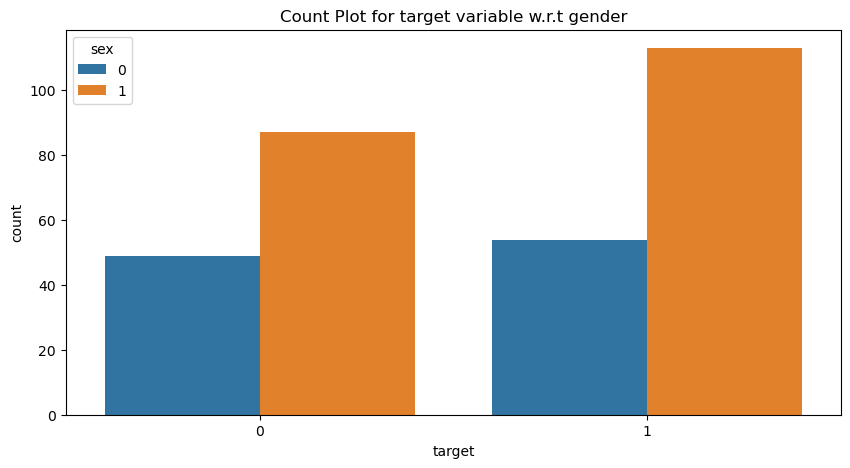

In [131]:
sns.countplot(data=df, x='target', hue='sex')
plt.title("Count Plot for target variable w.r.t gender")
plt.show()


In [132]:
df.duplicated().sum()


0

In [133]:
df.shape


(303, 14)

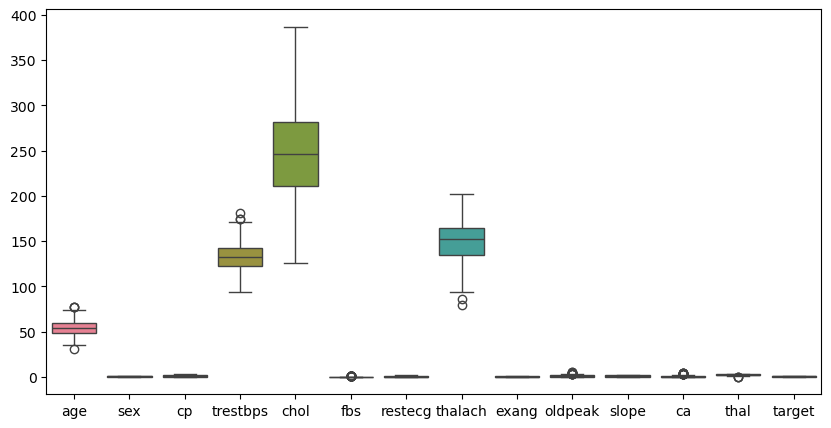

In [134]:
sns.boxplot(data=df)
plt.show()


In [135]:
Q1 = df.quantile(0.25)    
Q3 = df.quantile(0.75)    
IQR = Q3 - Q1                   
print(IQR)


age         11.0
sex          1.0
cp           2.0
trestbps    20.0
chol        70.5
fbs          0.0
restecg      1.0
thalach     30.0
exang        1.0
oldpeak      1.2
slope        2.0
ca           1.0
thal         1.0
target       1.0
dtype: float64


In [136]:
ll = Q1 - 1.5 * IQR
ul = Q3 + 1.5 * IQR

In [137]:
df = df[-((df < ll) | (df > ul)).any(axis=1)]

In [138]:
df.shape

(220, 14)

In [139]:
df

,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,target
2,41,0,1,130,204,0,0,172,0,1.4,2,0,2,1
3,56,1,1,120,236,0,1,178,0,0.8,2,0,2,1
4,57,0,0,120,354,0,1,163,1,0.6,2,0,2,1
5,43,0,0,126,198,0,1,108,1,2.1,2,0,2,1
6,56,1,3,150,323,0,0,185,0,3.2,2,0,1,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
297,51,0,3,126,256,0,1,105,1,0.8,1,0,3,0
298,38,0,0,138,214,0,0,166,0,0.3,1,0,2,0
300,70,0,0,129,214,0,1,157,0,1.4,1,0,2,1
301,40,0,1,158,191,0,1,129,0,1.0,0,1,1,0


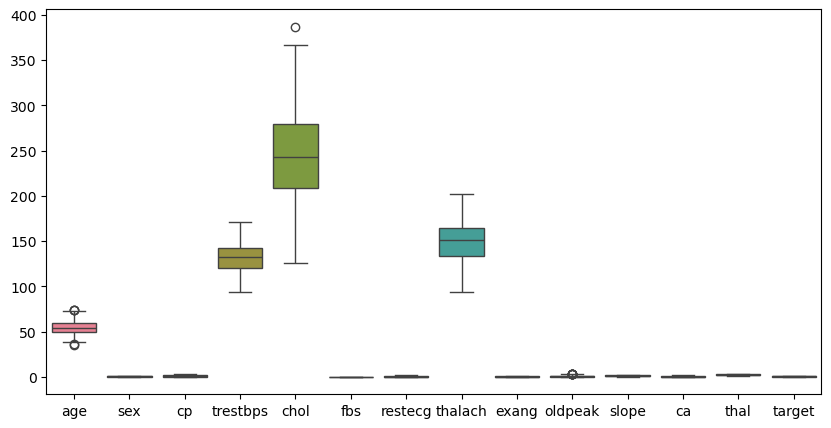

In [140]:
sns.boxplot(data=df)
plt.show()

In [141]:
X = df.drop('target', axis=1)
y = df['target']

In [142]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()
X = scaler.fit_transform(X)

In [143]:
from sklearn.model_selection import train_test_split

In [144]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=2
)

In [145]:
from sklearn.linear_model import LogisticRegression

In [146]:
logistic_model = LogisticRegression()

In [147]:
logistic_model.fit(X_train, y_train)

LogisticRegression()

In [148]:
logistic_model.score(X_train, y_train)

0.6363636363636364

In [149]:
logistic_model.score(X_test, y_test)

0.5454545454545454

In [150]:
y_predict = logistic_model.predict(X_test)

In [151]:
from sklearn.metrics import confusion_matrix, accuracy_score, recall_score, precision_score, f1_score

In [152]:
confusion_matrix(y_test, y_predict)

array([[ 9, 15],
       [ 5, 15]], dtype=int64)

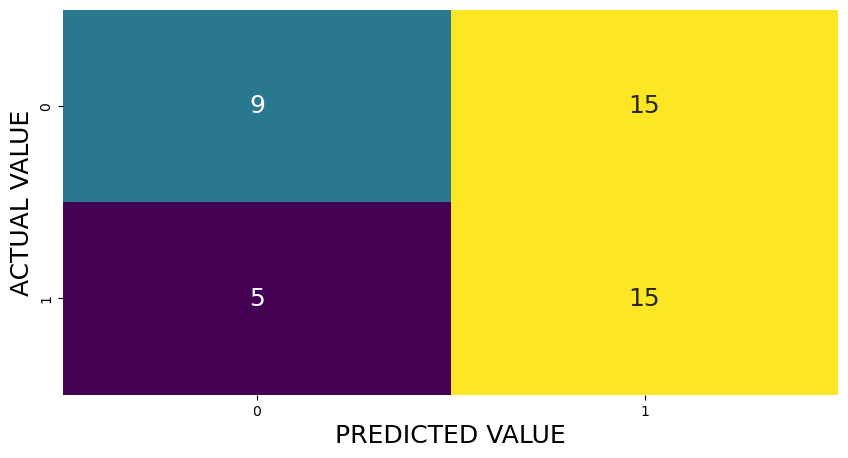

In [153]:
sns.heatmap(
    confusion_matrix(y_test, y_predict),
    annot=True,
    cbar=False,
    cmap='viridis',
    annot_kws={"fontsize":18}
)
plt.xlabel('PREDICTED VALUE', fontsize=18)
plt.ylabel('ACTUAL VALUE', fontsize=18)
plt.show()


In [154]:
accuracy_score(y_test, y_predict)

0.5454545454545454

In [155]:
precision_score(y_test, y_predict)

0.5

In [156]:
recall_score(y_test, y_predict)

0.75

In [157]:
f1_score(y_test, y_predict)

0.6